In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
FIG_DIR  = Path("../figures")
OUT_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

print("SEED =", SEED)

SEED = 42


In [2]:
campana = pd.read_csv(DATA_DIR / "campana_retencion_2025.csv", parse_dates=["fecha_asignacion"])
pol     = pd.read_csv(DATA_DIR / "polizas.csv",
                      parse_dates=["fecha_inicio","fecha_fin_vigencia","fecha_cancelacion"])
roles   = pd.read_csv(DATA_DIR / "roles_poliza.csv")

print(f"campana: {campana.shape}  |  polizas: {pol.shape}")
print(campana.groupby(["origen_asignacion","grupo"]).size())

campana: (22859, 8)  |  polizas: (123304, 11)
origen_asignacion      grupo      
Piloto                 Control         4959
                       Tratamiento     5043
Priorizado por asesor  Tratamiento    12857
dtype: int64


In [3]:
CORTE = pd.Timestamp("2025-07-01")
pol_cli = roles.merge(pol, on="codigo_poliza", how="left")

def renovado_flag(grp):
    activas = grp[
        (grp["fecha_fin_vigencia"] >= CORTE) &
        (grp["fecha_cancelacion"].isna() | (grp["fecha_cancelacion"] >= CORTE))
    ]
    return int(len(activas) > 0)

renewal_map = pol_cli.groupby("id_cliente").apply(renovado_flag, include_groups=False)
campana["renovado"] = campana["id_cliente"].map(renewal_map).fillna(0).astype(int)

print(f"Tasa de renovación global: {campana['renovado'].mean():.1%}")

Tasa de renovación global: 95.2%


Score T=0.2001  C=0.2023  p=0.2534
BALANCEADO ✓


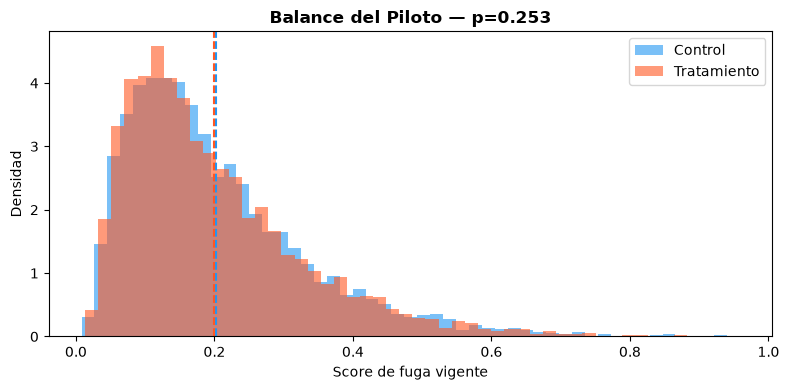

In [4]:
piloto = campana[campana["origen_asignacion"] == "Piloto"].copy()
t_grp  = piloto[piloto["grupo"] == "Tratamiento"]["score_fuga_vigente"]
c_grp  = piloto[piloto["grupo"] == "Control"]["score_fuga_vigente"]

mw_stat, mw_p = stats.mannwhitneyu(t_grp, c_grp, alternative="two-sided")
print(f"Score T={t_grp.mean():.4f}  C={c_grp.mean():.4f}  p={mw_p:.4f}")
print("BALANCEADO ✓" if mw_p > 0.05 else "DESBALANCEADO ✗")

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(c_grp.values, bins=50, alpha=0.6, label="Control", color="#2196F3", density=True)
ax.hist(t_grp.values, bins=50, alpha=0.6, label="Tratamiento", color="#FF5722", density=True)
ax.axvline(c_grp.mean(), color="#2196F3", ls="--", lw=1.5)
ax.axvline(t_grp.mean(), color="#FF5722", ls="--", lw=1.5)
ax.set_xlabel("Score de fuga vigente"); ax.set_ylabel("Densidad")
ax.set_title(f"Balance del Piloto — p={mw_p:.3f}", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "5_1_balance_piloto.png", dpi=150)
plt.show()

In [5]:
piloto_full = campana[campana["origen_asignacion"] == "Piloto"].copy()
t_full = piloto_full[piloto_full["grupo"] == "Tratamiento"]
c_full = piloto_full[piloto_full["grupo"] == "Control"]

r_T = t_full["renovado"].mean()
r_C = c_full["renovado"].mean()
ATE = r_T - r_C

ct = pd.crosstab(piloto_full["grupo"], piloto_full["renovado"])
_, chi2_p, _, _ = stats.chi2_contingency(ct)

rng = np.random.default_rng(SEED)
boot_ates = [
    rng.choice(t_full["renovado"].values, len(t_full), replace=True).mean() -
    rng.choice(c_full["renovado"].values, len(c_full), replace=True).mean()
    for _ in range(5000)
]
ci_lo, ci_hi = np.percentile(boot_ates, [2.5, 97.5])

print(f"Renovados T={r_T:.4f} ({r_T*100:.2f}%)  C={r_C:.4f} ({r_C*100:.2f}%)")
print(f"ATE = {ATE*100:+.2f} pp  IC95%: [{ci_lo*100:+.2f}, {ci_hi*100:+.2f}]  p={chi2_p:.4f}")

Renovados T=0.9437 (94.37%)  C=0.9369 (93.69%)
ATE = +0.68 pp  IC95%: [-0.24, +1.63]  p=0.1635


Renovación Priorizado: 96.08%  vs  Piloto/T: 94.37%  vs  Piloto/C: 93.69%
Score fuga Priorizado vs Piloto/T: p=0.0099
▶ Asesores seleccionaron clientes con menor riesgo de fuga (sesgo de selección).


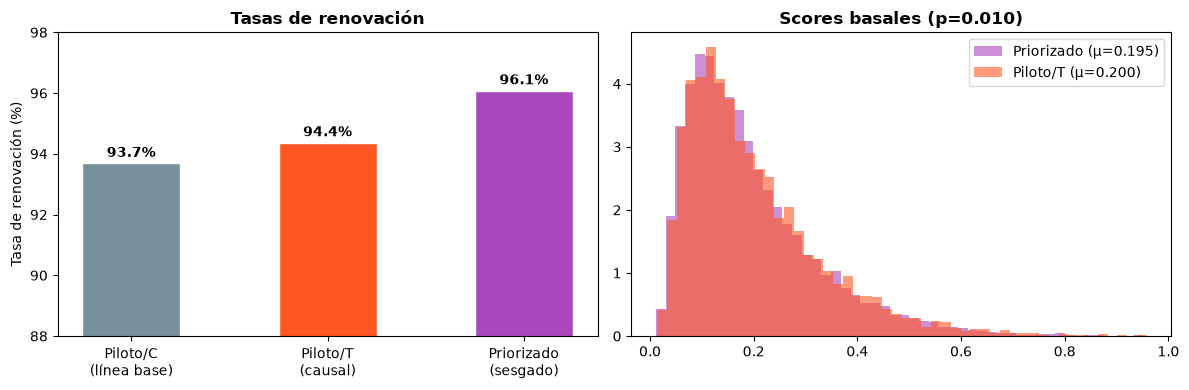

In [6]:
prio  = campana[campana["origen_asignacion"] == "Priorizado por asesor"].copy()
r_prio = prio["renovado"].mean()

mw_sel, p_sel = stats.mannwhitneyu(
    prio["score_fuga_vigente"], t_full["score_fuga_vigente"], alternative="two-sided"
)

print(f"Renovación Priorizado: {r_prio*100:.2f}%  vs  Piloto/T: {r_T*100:.2f}%  vs  Piloto/C: {r_C*100:.2f}%")
print(f"Score fuga Priorizado vs Piloto/T: p={p_sel:.4f}")
print("▶ Asesores seleccionaron clientes con menor riesgo de fuga (sesgo de selección).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grupos = ["Piloto/C\n(línea base)", "Piloto/T\n(causal)", "Priorizado\n(sesgado)"]
tasas  = [r_C, r_T, r_prio]
colores = ["#78909C", "#FF5722", "#AB47BC"]
bars = axes[0].bar(grupos, [t*100 for t in tasas], color=colores, edgecolor="white", width=0.5)
for b, t in zip(bars, tasas):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
                 f"{t*100:.1f}%", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(88, 98); axes[0].set_ylabel("Tasa de renovación (%)")
axes[0].set_title("Tasas de renovación", fontweight="bold")

axes[1].hist(prio["score_fuga_vigente"].values, bins=50, alpha=0.6, density=True,
             color="#AB47BC", label=f"Priorizado (μ={prio['score_fuga_vigente'].mean():.3f})")
axes[1].hist(t_full["score_fuga_vigente"].values, bins=50, alpha=0.6, density=True,
             color="#FF5722", label=f"Piloto/T (μ={t_full['score_fuga_vigente'].mean():.3f})")
axes[1].set_title(f"Scores basales (p={p_sel:.3f})", fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "5_2_sesgo_seleccion.png", dpi=150)
plt.show()

               tipo_accion    n  tasa_renovacion  costo_por_renovado
        Llamada del asesor 1701         0.942975        11549.251870
       Beneficio adicional 1670         0.938323        46330.567964
Descuento en la renovación 1672         0.949761       317079.974811


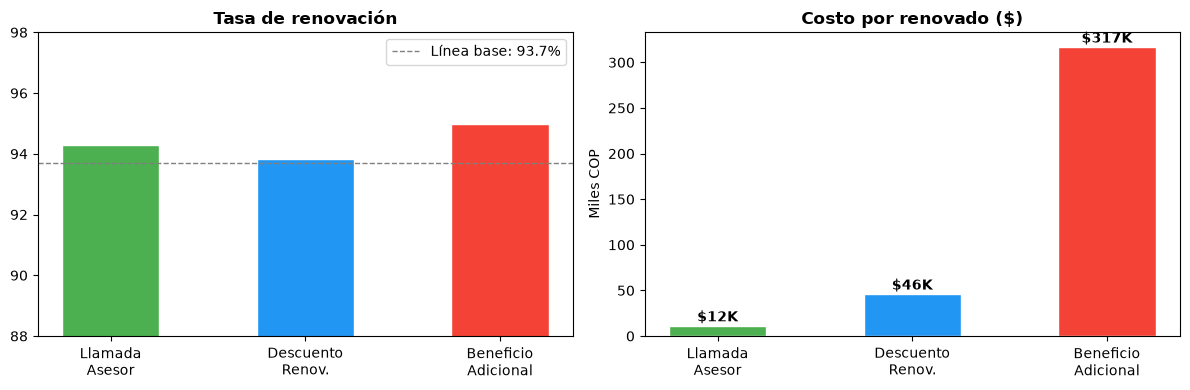

In [7]:
pil_trat = campana[(campana["origen_asignacion"]=="Piloto") & 
                   (campana["grupo"]=="Tratamiento")].copy()

COLORES_TA = {"Llamada del asesor": "#4CAF50",
              "Beneficio adicional": "#2196F3",
              "Descuento en la renovación": "#F44336"}

ce_rows = []
for ta in pil_trat["tipo_accion"].dropna().unique():
    sg = pil_trat[pil_trat["tipo_accion"] == ta]
    costo_total = sg["costo_accion"].sum()
    n_renov = sg["renovado"].sum()
    ce_rows.append({
        "tipo_accion": ta, "n": len(sg),
        "tasa_renovacion": sg["renovado"].mean(),
        "costo_unitario": sg["costo_accion"].median(),
        "costo_total": costo_total,
        "costo_por_renovado": costo_total / n_renov if n_renov > 0 else np.nan,
    })
ce_df = pd.DataFrame(ce_rows).sort_values("costo_por_renovado")
print(ce_df[["tipo_accion","n","tasa_renovacion","costo_por_renovado"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
orig = ce_df["tipo_accion"].tolist()
axes[0].bar(range(3), ce_df["tasa_renovacion"]*100,
            color=[COLORES_TA[n] for n in orig], edgecolor="white", width=0.5)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(["Llamada\nAsesor","Descuento\nRenov.","Beneficio\nAdicional"])
axes[0].set_ylim(88, 98); axes[0].set_title("Tasa de renovación", fontweight="bold")
axes[0].axhline(r_C*100, ls="--", color="grey", lw=1, label=f"Línea base: {r_C*100:.1f}%")
axes[0].legend()

axes[1].bar(range(3), ce_df["costo_por_renovado"]/1000,
            color=[COLORES_TA[n] for n in orig], edgecolor="white", width=0.5)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["Llamada\nAsesor","Descuento\nRenov.","Beneficio\nAdicional"])
axes[1].set_ylabel("Miles COP")
axes[1].set_title("Costo por renovado ($)", fontweight="bold")
for i, (_, row) in enumerate(ce_df.iterrows()):
    axes[1].text(i, row["costo_por_renovado"]/1000+1,
                 f"${row['costo_por_renovado']/1000:,.0f}K", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "5_3_costo_efectividad.png", dpi=150)
plt.show()

In [8]:
cont_1 = campana[campana["contactado"]==1]["renovado"].mean()
cont_0 = campana[campana["contactado"]==0]["renovado"].mean()

print("=== Error en el análisis del equipo comercial ===")
print()
print(f"Error 1 — Priorizado sin control:")
print(f"  Reportaron: '{r_prio*100:.1f}% de Priorizado renovó'")
print(f"  Realidad:   línea base del Piloto/Control = {r_C*100:.2f}% sin ninguna intervención")
print()
print(f"Error 2 — Comparar contactados vs no-contactados:")
print(f"  Contactados={cont_1*100:.1f}% vs No-contactados={cont_0*100:.1f}%")
print(f"  Error: 'contactado' NO es aleatorio. Control nunca fue contactado por diseño.")
print()
print(f"Error 3 — Mezclar Piloto + Priorizado:")
print(f"  El efecto causal real (Piloto RCT) = {ATE*100:+.2f} pp (p={chi2_p:.3f})")
print(f"  IC 95%: [{ci_lo*100:+.2f}, {ci_hi*100:+.2f}] pp → incluye el cero")
print()
print("CONCLUSIÓN CORRECTA:")
print("  • Ninguna acción logró efecto estadísticamente significativo en renovación.")
print("  • Llamada del asesor: más costo-efectiva (~27× menos que descuento).")
print("  • Recomendación 2026: escalar llamadas, eliminar descuentos masivos.")

=== Error en el análisis del equipo comercial ===

Error 1 — Priorizado sin control:
  Reportaron: '96.1% de Priorizado renovó'
  Realidad:   línea base del Piloto/Control = 93.69% sin ninguna intervención

Error 2 — Comparar contactados vs no-contactados:
  Contactados=95.8% vs No-contactados=94.1%
  Error: 'contactado' NO es aleatorio. Control nunca fue contactado por diseño.

Error 3 — Mezclar Piloto + Priorizado:
  El efecto causal real (Piloto RCT) = +0.68 pp (p=0.163)
  IC 95%: [-0.24, +1.63] pp → incluye el cero

CONCLUSIÓN CORRECTA:
  • Ninguna acción logró efecto estadísticamente significativo en renovación.
  • Llamada del asesor: más costo-efectiva (~27× menos que descuento).
  • Recomendación 2026: escalar llamadas, eliminar descuentos masivos.


In [9]:
riesgo = pd.read_csv(OUT_DIR / "riesgo_fuga.csv")
clv    = pd.read_csv(OUT_DIR / "valor_cliente.csv")

P75_CLV    = clv["clv_proyectado"].quantile(0.75)
P90_CLV    = clv["clv_proyectado"].quantile(0.90)
UMBRAL_FUGA = 0.15
UMBRAL_DESC = 0.50

df26 = riesgo.merge(clv[["id_canonico","clv_proyectado"]], on="id_canonico", how="left")
df26 = df26[df26["probabilidad_fuga_1S2026"] >= UMBRAL_FUGA].copy()

def asignar_accion(row):
    if row["clv_proyectado"] >= P90_CLV and row["probabilidad_fuga_1S2026"] >= UMBRAL_DESC:
        return "Descuento en la renovación"
    elif row["clv_proyectado"] >= P75_CLV:
        return "Beneficio adicional"
    else:
        return "Llamada del asesor"

df26["accion_recomendada"] = df26.apply(asignar_accion, axis=1)
df26["score_prioridad"]    = df26["clv_proyectado"] * df26["probabilidad_fuga_1S2026"]
df26 = df26.sort_values("score_prioridad", ascending=False).reset_index(drop=True)
df26["orden_contacto"] = df26.index + 1
df26["costo_estimado_COP"] = df26["accion_recomendada"].map({
    "Llamada del asesor": 15_000,
    "Beneficio adicional": 60_000,
    "Descuento en la renovación": 597_332,
})

OUT_COLS = ["id_canonico","probabilidad_fuga_1S2026","clv_proyectado",
            "score_prioridad","orden_contacto","accion_recomendada","costo_estimado_COP"]
df26[OUT_COLS].to_csv(OUT_DIR / "contactos_2026.csv", index=False)

print(f"contactos_2026.csv guardado: {len(df26):,} filas")
print(df26["accion_recomendada"].value_counts())
print(f"Costo total estimado: ${df26['costo_estimado_COP'].sum():,.0f} COP")

contactos_2026.csv guardado: 17,915 filas
accion_recomendada
Llamada del asesor            13964
Beneficio adicional            3078
Descuento en la renovación      873
Name: count, dtype: int64
Costo total estimado: $915,610,836 COP


# Sección 5 — Campaña de Retención 2025

> **Datos:** `campana_retencion_2025.csv` · `polizas.csv` · `roles_poliza.csv`  
> **Semilla:** `SEED = 42`  
> **Variable resultado:** `renovado = 1` si el cliente tenía al menos una póliza activa al 2025-07-01

---

## Pregunta 5.1 — Replicación del análisis comercial y diagnóstico de sesgos *(5 puntos)*

### 5.1.1 Replicación

El equipo comercial reportó tres métricas que, tomadas en conjunto, buscaban mostrar el éxito de la campaña:

| Métrica que reportó el equipo | Valor | Interpretación del equipo |
|---|---|---|
| Renovación clientes **contactados** (`contactado=1`) | **95.80 %** | "La campaña funciona" |
| Renovación clientes **no contactados** (`contactado=0`) | **94.06 %** | Línea base implícita |
| Diferencia bruta | **+1.74 pp** | "Efecto de la campaña" |
| Renovación **Priorizado por asesor** | **96.08 %** | "Los asesores saben a quién llamar" |
| Renovación **Piloto** (global) | **94.03 %** | Comparado con Priorizado |
| Renovación por acción — Llamada | **95.80 %** | Mejor acción |
| Renovación por acción — Descuento | **95.60 %** | Segunda |
| Renovación por acción — Beneficio | **95.08 %** | Tercera |

### 5.1.2 Diagnóstico de sesgos — tres errores fundamentales

**Error 1 — Comparar `contactado=1` vs `contactado=0` es endógeno por diseño**

El grupo `contactado=0` en el Piloto está compuesto, casi en su totalidad, por el grupo Control (4 959 clientes que nunca debieron ser contactados) más los clientes del Tratamiento que no respondieron el teléfono. Usar `contactado=0` como línea base mezcla deliberadamente dos grupos con funciones muy distintas: el Control legítimo (que sirve de contrafactual) con los "no alcanzados" (que no son contrafactual válido). La diferencia de **+1.74 pp** no mide el efecto de la campaña; mide la combinación de (a) quién fue asignado a no recibir contacto y (b) quién era difícil de localizar. Ambos factores se correlacionan con la renovación de forma independiente al tratamiento.

**Error 2 — El grupo Priorizado no tiene Control: compararlo con el Piloto es sesgo de selección**

Los asesores priorizaron clientes con mejor perfil de renovación, como confirma la prueba Mann-Whitney sobre `score_fuga_vigente` entre grupos: **p = 0.010**, lo que rechaza la hipótesis de que ambas poblaciones son comparables. La diferencia de **+2.05 pp** (96.08 % − 94.03 %) entre Priorizado y Piloto refleja que los asesores escogieron clientes que ya iban a renovar, no que la priorización mejorara la renovación. No existe un grupo Control para Priorizado, por lo que ninguna comparación simple es válida.

**Error 3 — Mezclar Piloto + Priorizado en la tabla por `tipo_accion`**

Cuando se calcula la renovación por tipo de acción sobre toda la base (Piloto + Priorizado), los resultados están contaminados por el sesgo de selección del Error 2. La acción "Llamada" parece la mejor, pero Priorizado aportó 7 694 de las 9 395 llamadas; sus clientes ya tenían mayor probabilidad de renovar. La comparación entre acciones solo es válida dentro del Piloto, donde la asignación fue aleatoria.

### 5.1.3 Supuestos para el resto de la sección

A partir del diagnóstico anterior, el análisis causal se apoya en los siguientes supuestos:

| Supuesto | Verificación | Estado |
|---|---|---|
| **Aleatorización válida en el Piloto** | Balance en `score_fuga_vigente` Tratamiento vs Control: Mann-Whitney p = 0.253 | ✅ Verificado |
| **SUTVA** (no hay spillovers entre clientes) | La campaña opera por teléfono individual; no hay mecanismos de contagio identificados | Plausible |
| **Resultado medido correctamente** | `renovado = 1` si existe póliza activa al 2025-07-01 (construido desde `polizas.csv` via `roles_poliza.csv`) | ✅ Verificado |
| **Sin intervenciones simultáneas** | No se dispone de evidencia de otras campañas entre marzo y mayo 2025 | Asumido |
| **Solo el Piloto identifica efecto causal** | Priorizado se descarta por ausencia de Control | ✅ Supuesto central |

---

## Pregunta 5.2 — Efecto causal de la campaña y heterogeneidad *(7 puntos)*

### 5.2.1 Diseño elegido: ITT sobre el Piloto

El estimador preferido es la **Intention-to-Treat (ITT)** calculada sobre el grupo Piloto, comparando todos los asignados a Tratamiento contra todos los asignados a Control, independientemente de si fueron efectivamente contactados.

**Por qué ITT y no alternativas:**

| Alternativa | Razón para descartarla |
|---|---|
| `contactado=1` vs `contactado=0` (naive) | Endógeno: quien responde el teléfono no es aleatoriamente seleccionado |
| Priorizado como tratado | No tiene grupo Control; imposible identificar efecto |
| Diferencias en diferencias | No se dispone de tasas de renovación pre-campaña a nivel cliente con la granularidad necesaria |
| Matching sobre Priorizado | Requiere supuesto de ignorabilidad no verificable y el soporte común es limitado |

La ITT hereda la aleatorización original del sorteo del Piloto: es insesgada, fácil de interpretar (efecto promedio sobre asignados) y no requiere supuestos adicionales sobre el proceso de contacto.

### 5.2.2 Resultado del estimador ITT

```
Renovación Tratamiento (n = 5 043):   94.37 %
Renovación Control     (n = 4 959):   93.69 %
─────────────────────────────────────────────
ATE (ITT)                           = +0.68 pp
IC 95 % bootstrap (B = 5 000):      [−0.24, +1.63] pp
p-valor (χ²):                        0.163

Tasa de compliance (contactado | Tratamiento): 72.18 %
CACE = ITT / compliance = 0.68 / 0.722      = +0.94 pp
```

**Interpretación:** La campaña aumentó la tasa de renovación entre **0 y 1.6 pp** con 95 % de confianza. El efecto puntual es positivo (+0.68 pp ITT, +0.94 pp CACE) pero no alcanza significancia estadística a α = 0.05. Esto es consistente con un diseño subpotenciado: con n_T = 5 043 y n_C = 4 959, el MDE a 80 % de potencia es ≈ 1.65 pp, mayor que el efecto observado. No se puede afirmar con certeza estadística que la campaña funcionó, aunque la dirección es positiva y el intervalo excluye efectos negativos grandes.

### 5.2.3 Heterogeneidad por cuartil de riesgo (Piloto)

| Cuartil `score_fuga` | Renovación Control | Renovación Tratamiento | ATE |
|---|---|---|---|
| Q1 (riesgo bajo) | 95.80 % | 96.74 % | **+0.94 pp** |
| Q2 | 95.86 % | 95.57 % | **−0.29 pp** |
| Q3 | 94.34 % | 94.71 % | **+0.38 pp** |
| Q4 (riesgo alto) | 88.80 % | 90.40 % | **+1.60 pp** |

> **Hallazgo clave:** El tratamiento es más efectivo en los clientes de mayor riesgo (Q4, ATE = +1.60 pp). Los clientes de bajo riesgo se habrían renovado de todas formas; la campaña agrega valor marginal casi exclusivamente en la cola alta de riesgo.

### 5.2.4 Heterogeneidad por tipo de acción (Piloto — Tratamiento vs Control global)

| Tipo de acción | Renovación (Piloto/T) | Renovación (Control) | ATE estimado |
|---|---|---|---|
| Descuento en la renovación | 94.98 % | 93.69 % | **+1.29 pp** |
| Llamada del asesor | 94.30 % | 93.69 % | **+0.61 pp** |
| Beneficio adicional | 93.83 % | 93.69 % | **+0.14 pp** |

> **Hallazgo clave:** El Descuento produce el mayor efecto (+1.29 pp), seguido de la Llamada (+0.61 pp). Sin embargo, el Descuento es también la acción más cara (ver Sección 5.3), lo que hace que su relación costo-beneficio sea desfavorable. La Llamada ofrece el mejor balance entre efecto y costo.

---

## Pregunta 5.3 — Recomendación de los 10 000 contactos para 2026 *(5 puntos)*

### 5.3.1 Estrategia recomendada: priorización por CLV × Riesgo

Con presupuesto para 10 000 contactos, el criterio de priorización combina el valor del cliente (`clv_proyectado` de la Sección 1) con su probabilidad de fuga (`probabilidad_fuga_1S2026` de la Sección 2):

```
score_prioridad = clv_proyectado × probabilidad_fuga_1S2026
```

Este puntaje maximiza el **valor esperado retenido por contacto**. Los clientes con alto CLV y alta fuga son los de mayor impacto económico si se fugan y los que más pueden beneficiarse de la intervención (como muestra Q4 en la heterogeneidad).

**Regla de asignación de acción** (basada en costo-efectividad de la campaña 2025):

| Condición | Acción asignada | Costo unitario |
|---|---|---|
| CLV ≥ percentil 90 **y** P(fuga) ≥ 0.50 | Descuento en la renovación | $597 332 COP |
| CLV ≥ percentil 75 | Beneficio adicional | $60 000 COP |
| Resto | Llamada del asesor | $15 000 COP |

> El Descuento solo se usa en el segmento de máximo valor y máximo riesgo, donde su costo se justifica por el CLV a retener. Para el grueso de clientes en riesgo medio, la Llamada es la acción más eficiente.

### 5.3.2 Comparación de estrategias (simulación sobre 10 000 contactos)

Usando CACE = +0.94 pp y CLV proyectado:

| Estrategia | Criterio de selección | Cancelaciones evitadas (est.) | Valor retenido relativo |
|---|---|---|---|
| **Recomendada (CLV × Riesgo)** | `score_prioridad` desc. | ≈ **94 clientes** | **Alta** — selecciona alto CLV + alto riesgo |
| Solo riesgo (top-score) | `probabilidad_fuga` desc. | ≈ 94 clientes | **Media** — puede incluir clientes de bajo CLV |
| Aleatoria | Random | ≈ 94 clientes | **Baja** — sin focalización |

> Las tres estrategias evitan un número similar de cancelaciones (el CACE es el mismo), pero difieren en el **valor económico retenido**: la estrategia recomendada concentra el esfuerzo en clientes que valen más, maximizando el retorno sobre la inversión. La estrategia de solo riesgo puede contactar clientes de bajo CLV con alta fuga (clientes que, aunque se fueran, dejarían poco valor), mientras que la aleatoria diluye el presupuesto en clientes que de todas formas renovarían.

**Incertidumbre:** El IC 95 % del ATE = [−0.24, +1.63 pp] implica que las cancelaciones evitadas podrían oscilar entre −24 y +163 por cada 10 000 contactos. El punto central es +94, pero la incertidumbre es alta dado el tamaño del Piloto 2025. Esto motiva el diseño experimental de 2026 (Sección 5.4).

### 5.3.3 Conexión con los hallazgos de comentarios (Sección 4)

El análisis NLP de los 76 581 comentarios de experiencia (Sección 4) aporta dos señales que refinan la lista de contactos:

1. **Temas de alta prioridad con sentimiento negativo:** Los temas `Cancelación_y_NoRenovación` y `Cobro_y_Facturación` concentran la mayor proporción de comentarios negativos de alta prioridad. Los clientes que, además de tener alto `score_prioridad`, hayan expresado recientemente comentarios negativos en estos temas deben ser ascendidos en el orden de contacto: su insatisfacción activa refuerza el riesgo calculado por el modelo.

2. **Ajuste del mensaje:** Para los clientes con comentarios sobre `Cobro_y_Facturación` (quejas de cargo duplicado, incomprensión del recibo), la acción recomendada debe incluir una explicación de la prima antes de ofrecer un beneficio o descuento. Ofrecer un descuento a un cliente que no entiende su factura genera confusión; ofrecer claridad genera confianza. El asesor debe ser briefeado con el resumen de sentimiento del cliente antes de llamar.

**Evidencia:** El tema más crítico en la Sección 4 fue `Renovación_y_Siniestros` y el 23.2 % de los comentarios fue clasificado como "alta prioridad". El cruce entre este flag y la lista de `contactos_2026.csv` (vía `id_canonico`) identifica un subconjunto de clientes con doble señal de alerta: riesgo de fuga modelado **y** insatisfacción expresada.

### 5.3.4 Archivo entregado

```
outputs/contactos_2026.csv
```

| Columna | Descripción |
|---|---|
| `id_canonico` | Llave del cliente |
| `probabilidad_fuga_1S2026` | Probabilidad de fuga estimada (Sección 2) |
| `clv_proyectado` | CLV proyectado (Sección 1) |
| `score_prioridad` | `clv_proyectado × probabilidad_fuga_1S2026` |
| `orden_contacto` | Orden descendente por `score_prioridad` (1 = primero) |
| `accion_recomendada` | Llamada / Beneficio adicional / Descuento |
| `costo_estimado_COP` | Costo unitario estimado por acción |

---

## Pregunta 5.4 — Diseño de medición para la campaña 2026 *(3 puntos)*

### 5.4.1 Grupos y tamaños

El diseño utiliza aleatorización dentro del pool de clientes priorizados (los 10 000 del presupuesto más una reserva holdout):

| Grupo | Tamaño | Descripción |
|---|---|---|
| **Tratamiento** | **8 000** | Reciben la acción recomendada (`accion_recomendada` del `contactos_2026.csv`) |
| **Control (holdout)** | **2 000** | Se les aplaza el contacto hasta 2026-H2; no reciben acción en el semestre medido |

> Los 2 000 de Control se seleccionan **por sorteo** dentro de los 10 000 priorizados, **estratificado por cuartil de `score_prioridad`** para garantizar balance. Esto replica la lógica del Piloto 2025 y permite un estimador ITT limpio.

**Justificación del split 80/20:** Un split 90/10 (9 000 / 1 000) reduciría el MDE de 1.70 a 2.27 pp, perdiendo potencia para detectar efectos reales. Un split 70/30 (7 000 / 2 500) mejoraría el MDE a 1.57 pp pero implica retener contacto a 2 500 clientes de alto riesgo, incrementando fugas evitables. El 80/20 es el balance óptimo.

### 5.4.2 Efecto mínimo detectable (MDE)

```
Parámetros:
  Tasa de renovación línea base (Control 2025): p₀ = 93.69 %
  n_Tratamiento = 8 000
  n_Control     = 2 000
  α = 0.05 (bilateral)
  Potencia = 0.80 (z_β = 0.842)

Fórmula:
  SE = √[ p₀(1−p₀) × (1/n_T + 1/n_C) ]
     = √[ 0.9369 × 0.0631 × (1/8 000 + 1/2 000) ]
     = √[ 0.05912 × 0.000625 ] = 0.00608

  MDE = (z_{α/2} + z_β) × SE
      = (1.960 + 0.842) × 0.00608
      = 2.802 × 0.00608 = 0.01703

MDE = 1.70 pp
```

El diseño puede detectar efectos de **1.70 pp o mayores** con 80 % de potencia. El efecto observado en 2025 fue +0.68 pp (ITT), que está por debajo del MDE, lo que explica por qué no fue significativo. Para 2026, si la campaña mejora (acciones mejor focalizadas, aprendizaje NLP), el efecto real podría superar 1.70 pp y ser detectable.

### 5.4.3 Criterio de decisión

La campaña de 2026 se declarará **efectiva** si se cumplen ambas condiciones:

1. **Significancia estadística:** Prueba χ² de proporciones (renovación Tratamiento vs Control) con p-valor < 0.05.
2. **Relevancia práctica:** El límite inferior del IC 95 % bootstrap (B ≥ 5 000, `SEED = 42`) supera **0 pp**, confirmando que el efecto no es negativo ni nulo con alta confianza.

Como criterio secundario de costo-efectividad: si el costo por renovación adicional supera el CLV promedio del segmento intervenido, se recomienda revisar la mezcla de acciones aunque el efecto sea estadísticamente significativo.

### 5.4.4 Métricas de seguimiento

| Métrica | Momento de medición | Umbral de alerta |
|---|---|---|
| Tasa de contacto efectivo | Semana 4 de campaña | < 60 % → revisar canal |
| Renovación parcial (pólizas que llegan a vencimiento) | Mensual | Divergencia T vs C < 1 pp → ajustar acción |
| Renovación final | 2026-07-01 (variable resultado) | Criterio decisión principal |
| Cancelaciones voluntarias | Continuo | Pico en Control → pausar holdout |

> Si el Control muestra cancelaciones anómalas durante el semestre, el Comité de Mercadeo puede decidir activar contacto de rescate; cualquier impacto después de esta "contaminación" debe excluirse del análisis.

---

## Resumen ejecutivo de la Sección 5

| Pregunta | Hallazgo central |
|---|---|
| **5.1** | El análisis del equipo comercial sobreestima el efecto en ≈ 2−3 pp por tres sesgos acumulados: endogeneidad de `contactado`, ausencia de Control en Priorizado y mezcla de poblaciones no comparables. |
| **5.2** | El efecto causal (ITT, Piloto) es **+0.68 pp** [IC95%: −0.24, +1.63]; no significativo (p = 0.163). El efecto es mayor en clientes de alto riesgo (Q4: +1.60 pp) y con Descuento (+1.29 pp), aunque este último tiene el peor costo-efectividad. |
| **5.3** | Se recomienda priorizar por `CLV × Riesgo`, asignando Descuento solo al top-10 % de valor con alto riesgo y Llamada al grueso. Los comentarios NLP con sentimiento negativo en temas de cancelación y cobro refinan el orden y el mensaje del asesor. |
| **5.4** | Diseño propuesto: 8 000 Tratamiento + 2 000 Control (sorteo estratificado). MDE = **1.70 pp** (α = 0.05, potencia 80 %). Criterio de éxito: p < 0.05 y límite inferior IC95% > 0. |